# Chapter 4 · Reduced-order models: a twin that runs in real time
**Level: Advanced** · ~40 min · 2D

Chapter 3's EnKF ran 40 full simulations every step. In real plants a twin must keep up with
the clock, often on modest hardware. The way out: a 64×64 field has 4,096 numbers, but the
fields a tank actually produces are **far more structured than random**. They are smooth blobs
being swirled and diffused. **Reduced-order models (ROMs)** find a few dozen patterns (*modes*)
and evolve only their weights:

$$c(x,y,t) \approx \bar c(x,y) + \sum_{i=1}^{r} a_i(t)\,\phi_i(x,y),\qquad r \ll n$$

| Tool | Question it answers |
|---|---|
| **POD** (proper orthogonal decomposition, i.e. SVD/PCA of snapshots) | which spatial patterns carry the energy? |
| **DMD** (dynamic mode decomposition) | which patterns oscillate or decay, and at which rates? |
| **Operator inference** | a small linear dynamical system $a_{k+1} = A_r a_k$ learned from data |
| **QR sensor placement** | where should $p$ sensors go to recover the $r$ modes? |
| **Reduced Kalman filter** | real-time data assimilation in mode space |

**Prerequisites:** Chapters 1–3, and the singular value decomposition (we recap it below).

## Glossary
| Term | Meaning |
|---|---|
| **snapshot** | the full field at one instant, flattened into a vector |
| **snapshot matrix** $X$ | snapshots stacked as rows: (number of snapshots) × (number of cells) |
| **SVD** | $X = U\Sigma V^\top$: any matrix as a sum of rank-one patterns, sorted by importance |
| **mode** $\phi_i$ | a spatial pattern (a column of $V$) |
| **singular value** $\sigma_i$ | how much of the data the mode explains. "Energy" is $\sigma_i^2$ |
| **rank** $r$ | how many modes we keep |
| **surrogate** | a fast model that imitates a slow one |

In [1]:
import sys; sys.path.insert(0, "..")
import time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML
from dtwin import viz
from dtwin.solvers import AdvDiff2D, random_blobs, Heat1D
from dtwin.rom import POD, DMD, qr_sensors, gappy_reconstruct
from dtwin.sensors import flat_to_xy
from dtwin.assimilation import KalmanFilter
viz.set_style()

## 0. Warm-up: compressing the heated rod of Chapter 1
Before 2D, the whole idea on data you already know. Simulate the rod with a heater that wanders
and changes power, store every snapshot as a **row** of $X$, and take the SVD.

**The SVD in one sentence:** $X = \sum_i \sigma_i\,\mathbf u_i \mathbf v_i^\top$. Each term is
*one spatial pattern* $\mathbf v_i$ (a mode) times *one time signal* $\sigma_i \mathbf u_i$ (its
weight over time). The terms come sorted from most to least important. Keep the first $r$ and you
have the **best possible** rank-$r$ approximation in the least-squares sense (Eckart-Young theorem).

snapshot matrix X: 751 snapshots x 121 cells
r = 1:  energy captured 81.2218%   relative error 4.33e-01
r = 2:  energy captured 95.4151%   relative error 2.14e-01
r = 3:  energy captured 98.7721%   relative error 1.11e-01
r = 5:  energy captured 99.8377%   relative error 4.03e-02
r = 8:  energy captured 99.9947%   relative error 7.26e-03


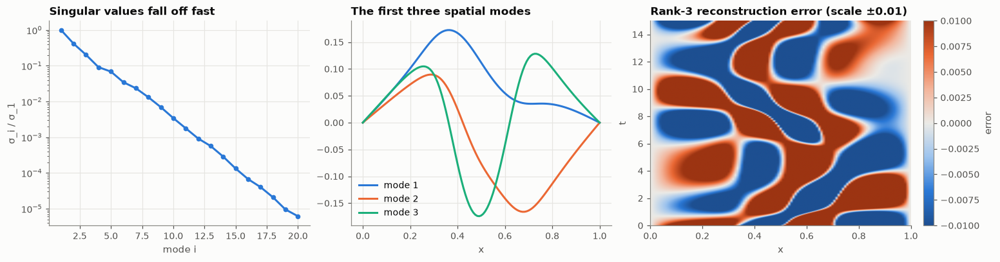

In [2]:
rod = Heat1D(nx=121, alpha=0.01, dt=0.02)
src = lambda x, t: (0.6 + 0.3 * np.sin(t)) * np.exp(-((x - 0.5 - 0.2 * np.sin(0.4 * t)) / 0.06) ** 2)
t_rod, X_rod = rod.simulate(np.zeros(121), 750, source=src)
pod_rod = POD().fit(X_rod)
print(f"snapshot matrix X: {X_rod.shape[0]} snapshots x {X_rod.shape[1]} cells")
for r in [1, 2, 3, 5, 8]:
    rec = pod_rod.decode(pod_rod.encode(X_rod, r))
    rel = np.linalg.norm(rec - X_rod) / np.linalg.norm(X_rod - pod_rod.mean)
    print(f"r = {r}:  energy captured {pod_rod.energy[r-1]:.4%}   relative error {rel:.2e}")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), constrained_layout=True)
axes[0].semilogy(np.arange(1, 21), pod_rod.singular_values[:20] / pod_rod.singular_values[0], "o-",
                 color=viz.TWIN, ms=4)
axes[0].set(xlabel="mode i", ylabel="σ_i / σ_1", title="Singular values fall off fast")
for i in range(3):
    axes[1].plot(rod.x, pod_rod.modes[:, i], color=viz.SERIES[i], label=f"mode {i+1}")
axes[1].set(xlabel="x", title="The first three spatial modes")
axes[1].legend()
r = 3
viz.spacetime(axes[2], pod_rod.decode(pod_rod.encode(X_rod, r)) - X_rod, rod.x, t_rod,
              cmap=viz.DIVERGING, vmin=-0.01, vmax=0.01, label="error")
axes[2].set_title(f"Rank-{r} reconstruction error (scale ±0.01)")
plt.show()

✅ **Check:** three numbers per instant, instead of 121, already capture 98.8% of the energy
(about 11% error), and eight numbers bring the error below 1%. Mode 1 looks like "the average hump", mode 2 like "the hump shifted left or right", and
mode 3 like "narrower or wider". POD discovers the physically meaningful degrees of freedom by
itself.

🔮 **Predict:** a sharp front that *moves* across the domain needs many more modes than this
wandering blob. Why?
<details><summary>Answer</summary>

A fixed set of spatial patterns has to represent a feature at every position it visits. A
narrow moving feature looks different at every instant, so the singular values decay slowly.
This is the *Kolmogorov n-width* problem mentioned at the end of this chapter.
</details>

Now the 2D tank.

In [3]:
rng = np.random.default_rng(21)

## 1. Training data: many runs of the full model
40 trajectories from random initial contaminations, 60 snapshots each (every 0.5 time units).
One extra trajectory is held out as the **test** case. The ensemble solver runs all of them at once.

2440 training snapshots of size 4096; full model: 43 ms per trajectory (batched)


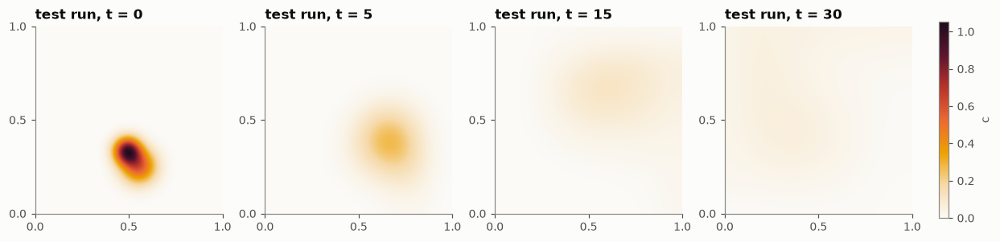

In [4]:
N_GRID = 64
fom = AdvDiff2D(n=N_GRID, kappa=1e-3, flow_amplitude=0.02, dt=0.025)   # full-order model
X, Y = fom.X, fom.Y
n_traj, save_every, T = 41, 20, 30.0
C0 = np.array([random_blobs(X, Y, rng, n_blobs=rng.integers(2, 5)) for _ in range(n_traj)])
t0 = time.time()
ts, C = fom.simulate(C0, T, save_every=save_every)     # (n_snap, n_traj, 64, 64)
fom_time = (time.time() - t0) / n_traj
C = C.transpose(1, 0, 2, 3)                            # (n_traj, n_snap, 64, 64)
train, test = C[:-1], C[-1]
dts = ts[1] - ts[0]
snapshots = train.reshape(-1, N_GRID**2)
print(f"{snapshots.shape[0]} training snapshots of size {snapshots.shape[1]}; "
      f"full model: {fom_time*1e3:.0f} ms per trajectory (batched)")

fig, axes = viz.snapshot_grid([test[i] for i in (0, 10, 30, 60)], [f"test run, t = {ts[i]:.0f}" for i in (0, 10, 30, 60)],
                              vmin=0, label="c", size=2.6)
plt.show()

## 2. POD: the energy is concentrated in a few modes
We do *not* subtract the mean here, because the dynamics are linear and homogeneous, so the
zero field must be representable.

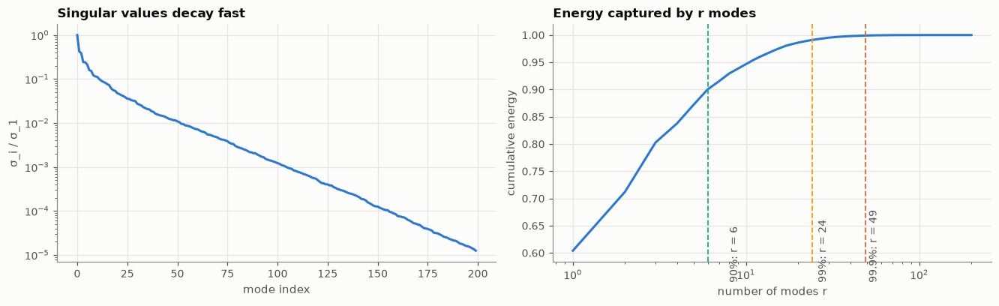

In [5]:
pod = POD().fit(snapshots, r=200, center=False)
r90, r99, r999 = (pod.rank_for(f) for f in (0.9, 0.99, 0.999))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), constrained_layout=True)
axes[0].semilogy(pod.singular_values[:200] / pod.singular_values[0], color=viz.TWIN)
axes[0].set(xlabel="mode index", ylabel="σ_i / σ_1", title="Singular values decay fast")
axes[1].plot(np.arange(1, 201), pod.energy[:200], color=viz.TWIN)
for r_, lab, col in [(r90, "90%", viz.AQUA), (r99, "99%", viz.YELLOW), (r999, "99.9%", viz.ORANGE)]:
    axes[1].axvline(r_, color=col, ls="--", lw=1.2)
    axes[1].text(r_ + 2, 0.55, f"{lab}: r = {r_}", color=viz.INK2, fontsize=9, rotation=90)
axes[1].set(xlabel="number of modes r", ylabel="cumulative energy", title="Energy captured by r modes",
            xscale="log")
plt.show()

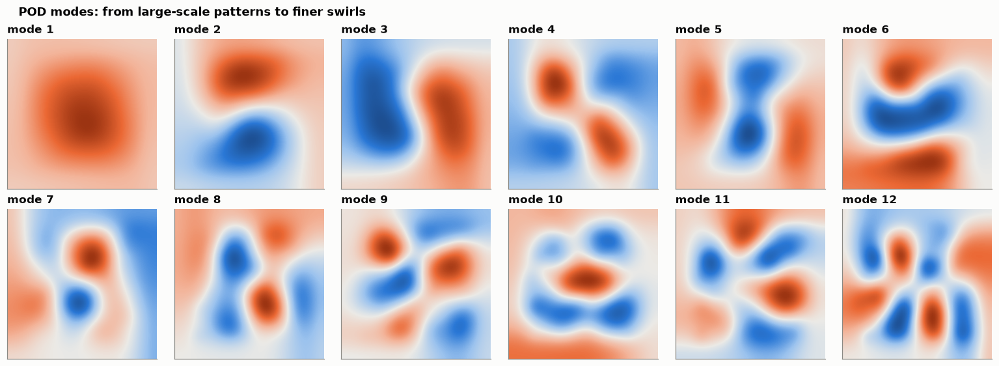

In [6]:
fig, axes = plt.subplots(2, 6, figsize=(14, 5), constrained_layout=True)
for i, ax in enumerate(axes.flat):
    m = pod.modes[:, i].reshape(N_GRID, N_GRID)
    lim = np.abs(m).max()
    viz.field(ax, m, cmap=viz.DIVERGING, vmin=-lim, vmax=lim, cbar=False, title=f"mode {i+1}")
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("POD modes: from large-scale patterns to finer swirls", x=0.02, ha="left", fontweight="bold")
viz.save(fig, "07_pod_modes.png")
plt.show()

## 3. How many modes do we need for the *test* run?

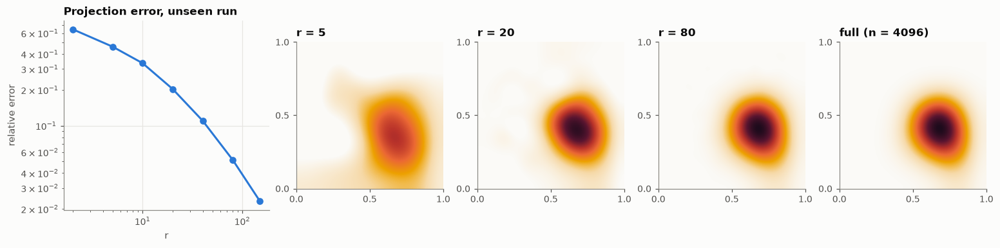

In [7]:
test_flat = test.reshape(len(ts), -1)
ranks = [2, 5, 10, 20, 40, 80, 150]
proj_err = [np.linalg.norm(pod.decode(pod.encode(test_flat, r)) - test_flat) / np.linalg.norm(test_flat) for r in ranks]

k = 12
fig = plt.figure(figsize=(14, 3.4), constrained_layout=True)
gs = fig.add_gridspec(1, 5, width_ratios=[1.4, 1, 1, 1, 1])
ax = fig.add_subplot(gs[0])
ax.loglog(ranks, proj_err, "o-", color=viz.TWIN)
ax.set(xlabel="r", ylabel="relative error", title="Projection error, unseen run")
vmax = test[k].max()
for j, r_ in enumerate([5, 20, 80]):
    rec = pod.decode(pod.encode(test_flat[k], r_)).reshape(N_GRID, N_GRID)
    viz.field(fig.add_subplot(gs[j + 1]), rec, vmin=0, vmax=vmax, cbar=False, title=f"r = {r_}")
viz.field(fig.add_subplot(gs[4]), test[k], vmin=0, vmax=vmax, cbar=False, title=f"full (n = {N_GRID**2})")
plt.show()

## 4. DMD: dynamics as decaying, rotating modes
DMD fits the best linear map $x_{k+1}\approx A x_k$ from one trajectory and diagonalises it.
Each eigenvalue $\lambda_j$ says how a mode evolves per step: $|\lambda_j|<1$ decays, and
$\arg\lambda_j$ is a rotation frequency (the vortex turning the plume).

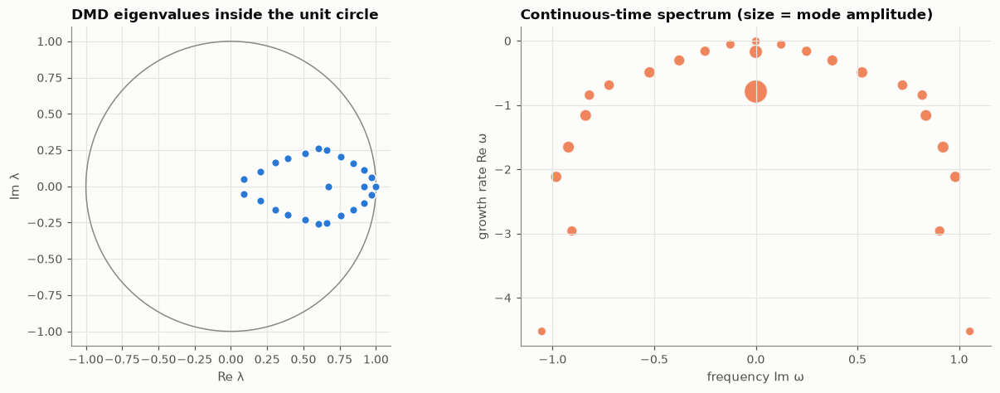

In [8]:
dmd = DMD().fit(test_flat[:40], r=25, dt=dts)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
th = np.linspace(0, 2 * np.pi, 300)
axes[0].plot(np.cos(th), np.sin(th), color=viz.MUTED, lw=1)
axes[0].scatter(dmd.eigs.real, dmd.eigs.imag, s=40, color=viz.TWIN, edgecolor="white", zorder=3)
axes[0].set(aspect="equal", xlabel="Re λ", ylabel="Im λ", title="DMD eigenvalues inside the unit circle")
axes[1].scatter(dmd.omega.imag, dmd.omega.real, s=40 + 300 * np.abs(dmd.b) / np.abs(dmd.b).max(),
                color=viz.ORANGE, edgecolor="white", alpha=0.8)
axes[1].set(xlabel="frequency Im ω", ylabel="growth rate Re ω",
            title="Continuous-time spectrum (size = mode amplitude)")
plt.show()

pred = dmd.predict(len(ts))   # snapshots 0-39 are a fit, 40+ are an extrapolation
dmd_err = np.linalg.norm(pred - test_flat, axis=1) / np.linalg.norm(test_flat, axis=1)

## 5. Operator inference: a ROM that generalises to new initial conditions
DMD from one trajectory only knows that trajectory. Instead, learn a reduced linear operator
$A_r$ from **all** training runs in POD coordinates:
$$a_{k+1} = A_r a_k,\qquad A_r = \arg\min \sum\|a_{k+1}-A_r a_k\|^2$$
Then forecast the unseen test run from its initial condition only, and compare speed.

max |eig(A_r)| = 1.0000  (<= 1: stable; the eigenvalue 1 is mass conservation)


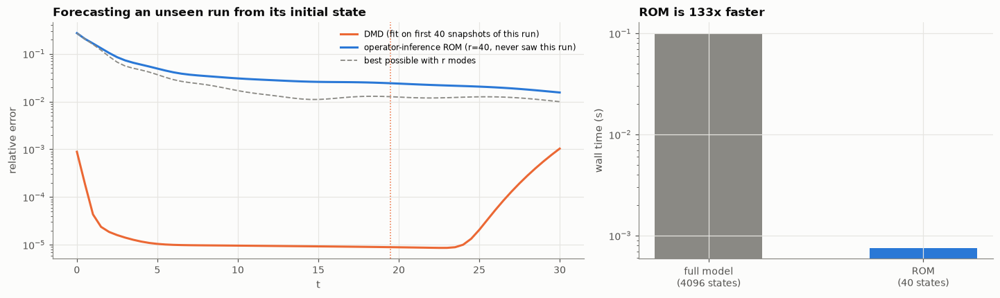

In [9]:
R = 40
Phi = pod.modes[:, :R]
A_tr = pod.encode(train.reshape(-1, N_GRID**2), R).reshape(train.shape[0], len(ts), R)
A0, A1 = A_tr[:, :-1].reshape(-1, R), A_tr[:, 1:].reshape(-1, R)
Ar = np.linalg.lstsq(A0, A1, rcond=None)[0].T
print(f"max |eig(A_r)| = {np.abs(np.linalg.eigvals(Ar)).max():.4f}  (<= 1: stable; the eigenvalue 1 is mass conservation)")

t0 = time.time()
a = [Phi.T @ test_flat[0]]
for _ in range(len(ts) - 1):
    a.append(Ar @ a[-1])
rom_pred = np.array(a) @ Phi.T
rom_time = time.time() - t0
t0 = time.time()
fom.simulate(C0[-1], T, save_every=save_every)
fom_single = time.time() - t0
rom_err = np.linalg.norm(rom_pred - test_flat, axis=1) / np.linalg.norm(test_flat, axis=1)
proj_floor = np.linalg.norm(Phi @ (Phi.T @ test_flat.T) - test_flat.T, axis=0) / np.linalg.norm(test_flat, axis=1)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), constrained_layout=True, gridspec_kw={"width_ratios": [1.5, 1]})
axes[0].semilogy(ts, dmd_err, color=viz.ORANGE, label="DMD (fit on first 40 snapshots of this run)")
axes[0].axvline(ts[39], color=viz.ORANGE, ls=":", lw=1)
axes[0].semilogy(ts, rom_err, color=viz.TWIN, label=f"operator-inference ROM (r={R}, never saw this run)")
axes[0].semilogy(ts, proj_floor, color=viz.MUTED, ls="--", lw=1.2, label="best possible with r modes")
axes[0].set(xlabel="t", ylabel="relative error", title="Forecasting an unseen run from its initial state")
axes[0].legend(fontsize=8)
axes[1].bar(["full model\n(4096 states)", f"ROM\n({R} states)"], [fom_single, rom_time],
            color=[viz.MUTED, viz.TWIN], width=0.5)
axes[1].set(yscale="log", ylabel="wall time (s)", title=f"ROM is {fom_single/rom_time:.0f}x faster")
plt.show()

## 6. Where to put the sensors? QR pivoting
To recover $r$ mode coefficients from $p\ge r$ point sensors we solve
$y = \Phi_{[\text{sensors}]}\,a$ by least squares. The conditioning of $\Phi_{[\text{sensors}]}$
decides how much sensor noise gets amplified. **QR with column pivoting** on $\Phi^\top$ greedily
picks the rows that keep it well-conditioned (Manohar et al., 2018).

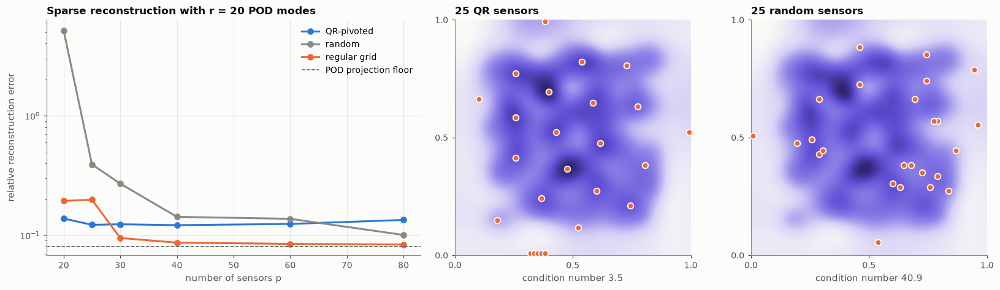

In [10]:
r_s = 20
Phi_s = pod.modes[:, :r_s]
zero = np.zeros(N_GRID**2)
noise = 0.002
ps = [20, 25, 30, 40, 60, 80]
layouts = {"QR-pivoted": lambda p: qr_sensors(Phi_s, p),
           "random": lambda p: rng.choice(N_GRID**2, p, replace=False),
           "regular grid": lambda p: (lambda q: (np.linspace(4, 59, q).round().astype(int)[:, None] * N_GRID
                                                 + np.linspace(4, 59, q).round().astype(int)[None]).ravel())(int(np.ceil(np.sqrt(p))))}
errs = {k: [] for k in layouts}
for name, f in layouts.items():
    for p in ps:
        e = []
        for trial in range(5 if name == "random" else 1):
            idx = f(p)
            rec = np.array([gappy_reconstruct(s[idx] + noise * rng.standard_normal(idx.size), idx, Phi_s, zero)
                            for s in test_flat[5:]])
            e.append(np.linalg.norm(rec - test_flat[5:]) / np.linalg.norm(test_flat[5:]))
        errs[name].append(np.median(e))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True, gridspec_kw={"width_ratios": [1.3, 1, 1]})
for i, (name, e) in enumerate(errs.items()):
    axes[0].semilogy(ps, e, "o-", color=[viz.TWIN, viz.MUTED, viz.ORANGE][i], label=name)
floor20 = np.linalg.norm(Phi_s @ (Phi_s.T @ test_flat[5:].T) - test_flat[5:].T) / np.linalg.norm(test_flat[5:])
axes[0].axhline(floor20, color=viz.INK2, ls="--", lw=1, label="POD projection floor")
axes[0].set(xlabel="number of sensors p", ylabel="relative reconstruction error",
            title=f"Sparse reconstruction with r = {r_s} POD modes")
axes[0].legend()
idx_qr = qr_sensors(Phi_s, 25)
idx_rand = rng.choice(N_GRID**2, 25, replace=False)
energy_map = np.sqrt((Phi_s**2).sum(1)).reshape(N_GRID, N_GRID)
for ax, idx, ttl in [(axes[1], idx_qr, "25 QR sensors"), (axes[2], idx_rand, "25 random sensors")]:
    viz.field(ax, energy_map, cmap=viz.UNCERTAINTY, cbar=False, title=ttl)
    xs_, ys_ = flat_to_xy(idx, N_GRID, fom.x)
    viz.sensors_2d(ax, xs_, ys_, s=40, facecolor=viz.ORANGE, edgecolor="white")
    cond = np.linalg.cond(Phi_s[idx])
    ax.set_xlabel(f"condition number {cond:.1f}")
plt.show()

**Reading the plot:**
* At a tight budget ($p \approx r$) QR wins by orders of magnitude. Random sensors often cluster,
  so $\Phi_{[\text{sensors}]}$ is nearly singular and noise is amplified enormously (condition numbers in the maps).
* With generous oversampling ($p \gg r$) any well-spread layout works, and the regular grid catches up.
* Nobody reaches the dashed floor: energy in the discarded modes **aliases** into the fitted
  coefficients. More sensors cannot fix this; only more modes (and then more sensors) can.

## 7. Putting it together: a reduced Kalman filter twin
Combine the ROM dynamics $A_r$ with the QR sensors: a Kalman filter in a 40-dimensional space
instead of 4,096. Unlike the full KF this costs microseconds per step. We start the twin from an
empty tank (it knows nothing about the initial contamination) and let 45 noisy QR sensors pull it in.

reduced KF: 4.78 ms per assimilation cycle (incl. lifting to the full field)


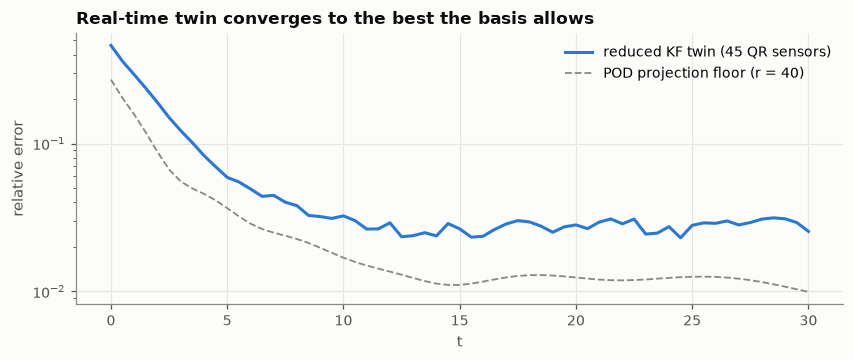

In [11]:
idx = qr_sensors(Phi, 45)
H_r = Phi[idx]
Q_r = np.diag(np.full(R, 1e-4))
kf = KalmanFilter(Ar, H_r, Q_r, np.eye(idx.size) * noise**2)
a_est, P = np.zeros(R), np.eye(R) * 0.5
est, sd = [], []
t0 = time.time()
for k in range(len(ts)):
    if k > 0:
        a_est, P = kf.predict(a_est, P)
    y = test_flat[k, idx] + noise * rng.standard_normal(idx.size)
    a_est, P, _, _ = kf.update(a_est, P, y)
    est.append(Phi @ a_est)
    sd.append(np.sqrt(np.einsum("ij,jk,ik->i", Phi, P, Phi)))
per_step = (time.time() - t0) / len(ts)
est, sd = np.array(est).reshape(-1, N_GRID, N_GRID), np.array(sd).reshape(-1, N_GRID, N_GRID)
kf_err = np.linalg.norm((est - test).reshape(len(ts), -1), axis=1) / np.linalg.norm(test_flat, axis=1)
print(f"reduced KF: {per_step*1e3:.2f} ms per assimilation cycle (incl. lifting to the full field)")

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.semilogy(ts, kf_err, color=viz.TWIN, label="reduced KF twin (45 QR sensors)")
ax.semilogy(ts, proj_floor, color=viz.MUTED, ls="--", lw=1.2, label="POD projection floor (r = 40)")
ax.set(xlabel="t", ylabel="relative error", title="Real-time twin converges to the best the basis allows")
ax.legend()
plt.show()

sx, sy = flat_to_xy(idx, N_GRID, fom.x)
sel = np.arange(0, len(ts), 1)
anim = viz.animate_2d([test[sel], est[sel], sd[sel]], ts[sel], ["Reality", "Reduced KF twin", "Twin std"],
                      cmaps=[viz.FIELD, viz.FIELD, viz.UNCERTAINTY],
                      vlims=[(0, test[2:].max()), (0, test[2:].max()), (0, sd[3:].max())],
                      sensors=(sx, sy), size=3.3, interval=150)
HTML(anim.to_jshtml())

## Recap
* Spatio-temporal fields are **compressible**: here 40 modes instead of 4,096 cells.
* POD gives the basis, DMD the spectral insight, and operator inference a fast predictive model.
* QR pivoting turns the basis into a **sensor-placement design** tool.
* ROM + Kalman filter = a twin that assimilates in about 10 ms per cycle, including
  rebuilding the full 4,096-cell field.

**Caveats (expert):** linear ROMs struggle with strongly advective, moving sharp fronts (the
Kolmogorov n-width problem). They are only as good as the training data's coverage. A change of
physics (a new κ, a leak) moves the field off the training manifold, and detecting exactly that
is a job for the capstone (Chapter 6).

## Quick quiz
1. 99% of the energy is in 10 modes. Does that guarantee 1% error on a *new* run?
2. Why do QR-chosen sensors beat a regular grid for the same count?
3. What does a DMD eigenvalue with $|\lambda| < 1$ and a nonzero angle mean physically?

<details><summary>Answers</summary>

1. No. The energy is measured on the training data; a run unlike them (new physics, new source)
   can fall outside the basis.
2. QR puts sensors where the modes are most distinguishable from one another, so the inversion
   from readings to mode weights is well-conditioned.
3. A pattern that rotates (oscillates) while it decays, like the swirl of the stirred tank.
</details>

## Exercises
1. Raise Pe (κ = 1e-4). How many modes are now needed for 99% energy?
2. Train the ROM on 10 trajectories instead of 40. What happens to the test error?
3. In the warm-up, make the heater jump between two positions. How fast do the singular values decay now?